# Exploring Scada Dataset

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.optimize import least_squares

In [27]:
scada_noloss = pd.read_parquet('../../data/cleaned/scada_noloss.parquet')
reference = pd.read_parquet('../../data/cleaned/reference_power_curve.parquet')

In [32]:
reference_low = reference[reference['air_density_ref'] == 1.225]

In [9]:
scada_noloss.shape

(1624407, 19)

In [81]:
df = scada_noloss.copy()

In [79]:
rated, cut_in, cut_out = 2850, 3.0, 25.0  # kW, m/s
df = df.dropna(subset=['wind_speed', 'KPI_real_power_ac'])
df = df[
    ~((df.KPI_real_power_ac <= 0) & (df.wind_speed > cut_in))                  # stopped / downtime
    & (df.KPI_real_power_ac <= 1.05 * rated)                                   # impossible output
    & ~((df.KPI_real_power_ac > 0.05 * rated) & (df.wind_speed < cut_in - 1))  # power with no wind
    & (df.wind_speed < cut_out)
]

In [82]:
rated, cut_in, cut_out = 2850, 3.0, 25.0  # kW, m/s
p, ws = df['KPI_real_power_ac'], df['wind_speed']

df['flag'] = (
    p.isna() | ws.isna()                              # missing data
    | ((p <= 0) & (ws > cut_in))                      # stopped / downtime
    | (p > 1.05 * rated)                              # impossible output
    | ((p > 0.05 * rated) & (ws < cut_in - 1))        # power with no wind
    | (ws >= cut_out)                                 # above cut-out
)

In [8]:
df.shape

(1351235, 19)

In [11]:
same = df.KPI_real_power_ac.diff().eq(0).astype(int).rolling(6).sum().eq(6)
df = df[~(same & (df.KPI_real_power_ac < 0.95 * rated))]

In [12]:
df.shape

(1177273, 19)

In [99]:
scada_noloss['flag'] = scada_noloss['KPI_real_power_ac'] > scada_noloss['KPI_theoretical_power'] + 0.4 * 2850

In [121]:
frac = (0.06 * scada_noloss['wind_speed']).clip(lower = 0.02, upper = 0.6)
scada_noloss['flag'] = (
    (scada_noloss['KPI_real_power_ac'] > scada_noloss['KPI_theoretical_power'] + frac * 2850)
    | ((scada_noloss['KPI_real_power_ac'] <= 0) & (scada_noloss['wind_speed'] > 5))
)

In [150]:
ws_pts   = [3,    5,    7,    9,    11,   13]
frac_pts = [0.06, 0.2, 0.35, 0.5, 0.6, 0.75]
frac = np.interp(scada_noloss['wind_speed'], ws_pts, frac_pts)

scada_noloss['flag'] = (
    (scada_noloss['KPI_real_power_ac'] > scada_noloss['KPI_theoretical_power'] + frac * 2850)
    | ((scada_noloss['KPI_real_power_ac'] <= 0) & (scada_noloss['wind_speed'] > 5))
)

In [151]:
a = scada_noloss[scada_noloss['flag']]

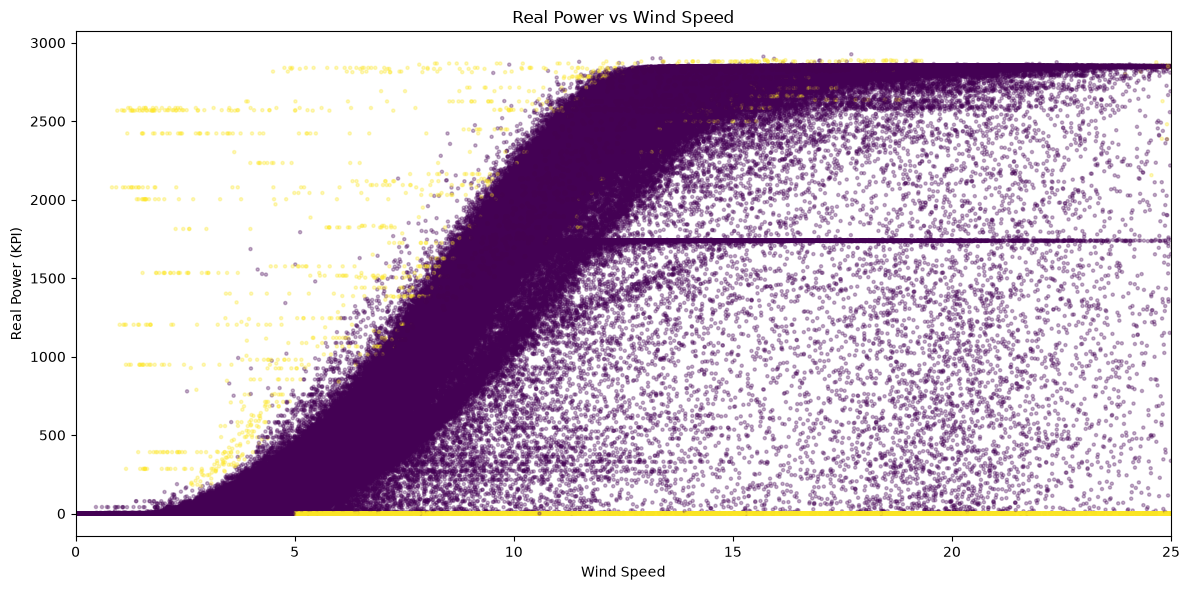

In [153]:
plt.figure(figsize = (12, 6))
sc = plt.scatter(scada_noloss['wind_speed'], scada_noloss['KPI_real_power_ac'], c = scada_noloss['flag'], alpha = 0.3, s = 5)
plt.xlabel('Wind Speed')
plt.ylabel('Real Power (KPI)')
plt.title('Real Power vs Wind Speed')
plt.xlim(0, 25)
plt.tight_layout()
plt.show()

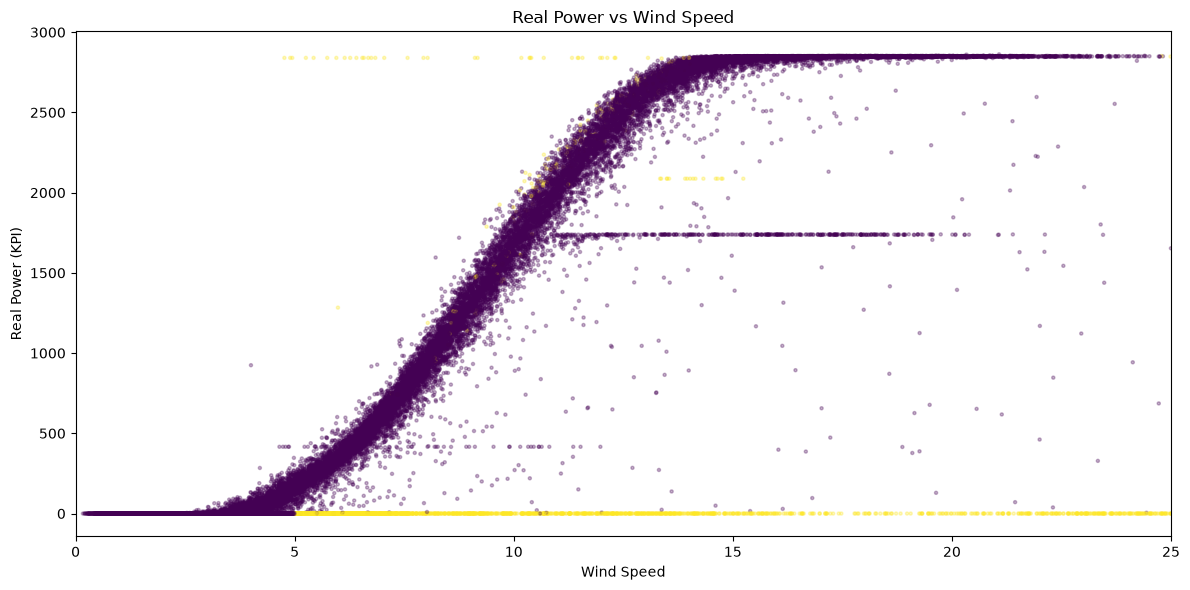

In [94]:
turbine = 'WTG155'

z = scada_noloss[scada_noloss['turbine'] == turbine]

plt.figure(figsize = (12, 6))
sc = plt.scatter(z['wind_speed'], z['KPI_real_power_ac'], c = z['flag'], alpha = 0.3, s = 5)
plt.xlabel('Wind Speed')
plt.ylabel('Real Power (KPI)')
plt.title('Real Power vs Wind Speed')
plt.xlim(0, 25)
plt.tight_layout()
plt.show()

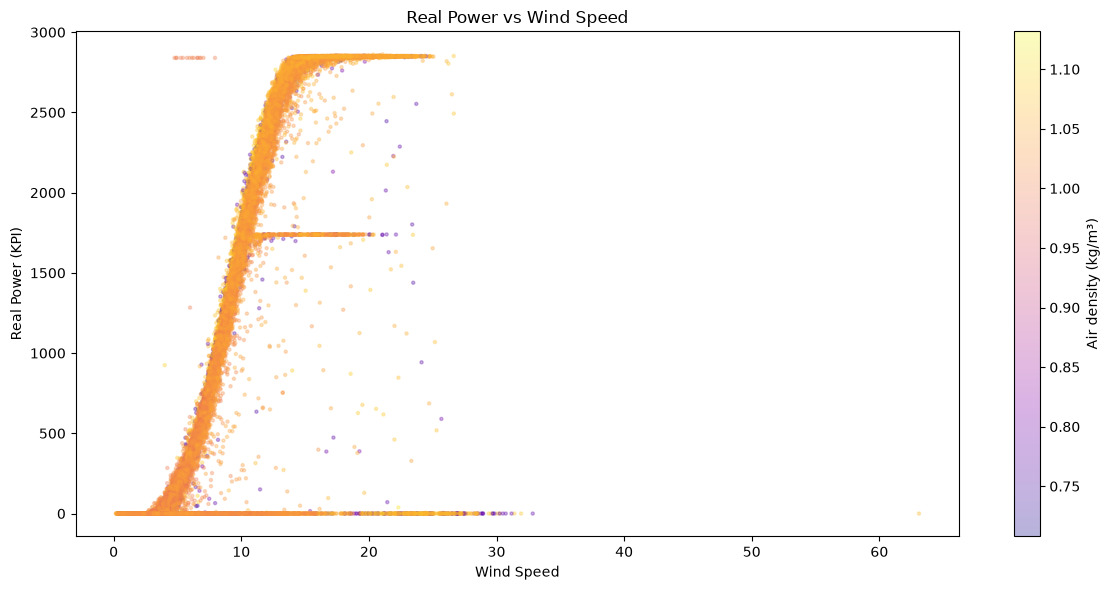

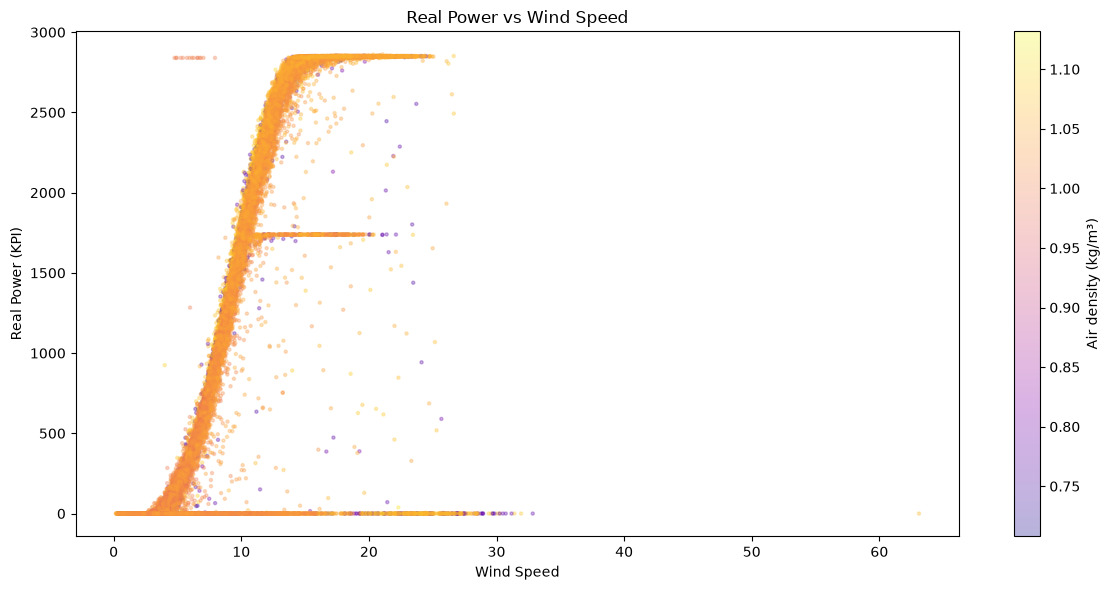

In [83]:
turbine = 'WTG155'

a = scada_noloss[scada_noloss['turbine'] == turbine]
b = df[df['turbine'] == turbine]

plt.figure(figsize = (12, 6))
sc = plt.scatter(a['wind_speed'], a['KPI_real_power_ac'], c = a['air_density'], cmap = 'plasma', alpha = 0.3, s = 5)
plt.colorbar(sc, label = 'Air density (kg/m³)')
plt.xlabel('Wind Speed')
plt.ylabel('Real Power (KPI)')
plt.title('Real Power vs Wind Speed')
plt.tight_layout()
plt.show()

plt.figure(figsize = (12, 6))
sc = plt.scatter(b['wind_speed'], b['KPI_real_power_ac'], c = b['air_density'], cmap = 'plasma', alpha = 0.3, s = 5)
plt.colorbar(sc, label = 'Air density (kg/m³)')
plt.xlabel('Wind Speed')
plt.ylabel('Real Power (KPI)')
plt.title('Real Power vs Wind Speed')
plt.tight_layout()
plt.show()

In [42]:
WIND_COL = "wind_speed"
POWER_COL = "KPI_real_power_ac"
RATED_KW = 2850      # from the turbine datasheet
CUT_IN = 3.0           # m/s
CUT_OUT = 25.0         # m/s
FIX_RATED = False

In [43]:
def logistic_curve(v, p_max, k, v0, g):
    """Generalized logistic S-curve.
    p_max: upper plateau (~rated power)
    k:     steepness of the ramp
    v0:    wind speed near the middle of the ramp
    g:     asymmetry (1 = symmetric; real curves are usually asymmetric)
    """
    z = np.clip(-k * (np.asarray(v, float) - v0), -50, 50)
    return p_max / (1.0 + np.exp(z)) ** g

In [52]:
logistic_curve(x, 2850, 2000, 7.5, 1)

array([5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 5.49693707e-19, 5.49693707e-19,
       5.49693707e-19, 5.49693707e-19, 2.85000000e+03, 2.85000000e+03,
       2.85000000e+03, 2.85000000e+03, 2.85000000e+03, 2.85000000e+03,
      